# Chapter 1 — The Toy Example: How the Same Voters Can Elect Two Different Winners

## The story so far

In America, voters are supposed to choose their politicians. In many districts, it's the other way around. This chapter shows how — with just 25 voters.

**A district** is simply a patch of map that elects one representative. Every ten years, after the Census counts everyone, each state redraws its districts. Whoever holds the pen decides which voters go in which district. The votes don't change. The lines do. And the winner changes with them.

Run every cell top to bottom. No dataset to download for this chapter — we build the voters ourselves.


In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 25 voters on a 5x5 grid. 'A' votes for Party A, 'B' votes for Party B.
# Total: 13 votes for A, 12 votes for B. A has a small majority: 52% of the vote.
grid = [
    ['A', 'A', 'A', 'B', 'A'],
    ['A', 'B', 'B', 'A', 'A'],
    ['B', 'A', 'B', 'A', 'A'],
    ['B', 'B', 'A', 'A', 'A'],
    ['B', 'B', 'B', 'B', 'B'],
]
df = pd.DataFrame(grid)
print('The neighborhood: 25 voters')
print(df.to_string(index=False, header=False))
print()
print('Votes for A:', sum(row.count('A') for row in grid))
print('Votes for B:', sum(row.count('B') for row in grid))
print('Vote share: A =', round(13 / 25 * 100, 1), '%, B =', round(12 / 25 * 100, 1), '%')

The neighborhood: 25 voters
A A A B A
A B B A A
B A B A A
B B A A A
B B B B B

Votes for A: 13
Votes for B: 12
Vote share: A = 52.0 %, B = 48.0 %


## Two ways to draw the map

A state has to split these 25 voters into **5 districts of 5 voters each**. There are many ways to do it. Let's try two.

- **Map 1 — districts are the ROWS.** Each row of the grid is one district.
- **Map 2 — districts are the COLUMNS.** Each column of the grid is one district.

Same voters. Same votes. Different lines. Watch what happens to the winner.


In [3]:
def district_result(votes):
    """Return (winner, winner_votes, loser_votes) for one district."""
    a = votes.count('A')
    b = votes.count('B')
    if a > b:
        return 'A', a, b
    return 'B', b, a


def run_election(districts, name):
    seats = {'A': 0, 'B': 0}
    print(f'--- {name} ---')
    for i, d in enumerate(districts, start=1):
        winner, wv, lv = district_result(d)
        seats[winner] += 1
        print(f'District {i}: ' + '-'.join(d) + f' -> {winner} wins {wv}-{lv}')
    print(f'Seats: A = {seats["A"]}, B = {seats["B"]}')
    return seats


# Map 1: rows are districts
rows = [list(r) for r in grid]
seats_rows = run_election(rows, 'MAP 1: districts are ROWS')
print()
# Map 2: columns are districts
cols = [[grid[r][c] for r in range(5)] for c in range(5)]
seats_cols = run_election(cols, 'MAP 2: districts are COLUMNS')

--- MAP 1: districts are ROWS ---
District 1: A-A-A-B-A -> A wins 4-1
District 2: A-B-B-A-A -> A wins 3-2
District 3: B-A-B-A-A -> A wins 3-2
District 4: B-B-A-A-A -> A wins 3-2
District 5: B-B-B-B-B -> B wins 5-0
Seats: A = 4, B = 1

--- MAP 2: districts are COLUMNS ---
District 1: A-A-B-B-B -> B wins 3-2
District 2: A-B-A-B-B -> B wins 3-2
District 3: A-B-B-A-B -> B wins 3-2
District 4: B-A-A-A-B -> A wins 3-2
District 5: A-A-A-A-B -> A wins 4-1
Seats: A = 2, B = 3


## Packing and cracking, in plain words

Look at Map 1. Party A wins **4 of 5 seats with only 52% of the votes**. How? Two tricks were used against Party B:

- **Packing:** B's voters were stuffed into a single district (row 5: B wins 5–0). Those extra B votes are wasted — B only needed 3 to win that district, so the extra 2 votes buy nothing.
- **Cracking:** B's remaining voters were spread thinly across the other four districts, where they lose every time (1–4, 2–3, 2–3, 2–3). Every one of those B votes is also wasted, because they never elect anyone.

In Map 2 the same voters, grouped differently, give B a 3–2 win. **Nobody changed their vote. Only the lines moved.** That is gerrymandering.


In [4]:
def efficiency_gap(districts):
    """
    Wasted votes = votes that did not help elect anyone:
      - every vote for the loser, plus
      - every vote for the winner above what the winner needed to win.
    In a 5-voter district the winner needs 3 votes, so surplus = winner_votes - 3.
    Efficiency gap = (wasted_B - wasted_A) / total_votes.
    Positive = the map favors A; negative = it favors B.
    """
    wasted = {'A': 0, 'B': 0}
    total = 0
    for d in districts:
        winner, wv, lv = district_result(d)
        loser = 'B' if winner == 'A' else 'A'
        wasted[winner] += wv - 3  # surplus votes beyond the 3 needed
        wasted[loser] += lv        # every vote for the loser is wasted
        total += len(d)
    gap = (wasted['B'] - wasted['A']) / total
    return wasted, gap


w_rows, gap_rows = efficiency_gap(rows)
w_cols, gap_cols = efficiency_gap(cols)
print('MAP 1 (rows): wasted votes A =', w_rows['A'], ', B =', w_rows['B'])
print('  Efficiency gap =', round(gap_rows * 100, 1), '%  -> the map favors A')
print()
print('MAP 2 (columns): wasted votes A =', w_cols['A'], ', B =', w_cols['B'])
print('  Efficiency gap =', round(gap_cols * 100, 1), '%  -> the map favors B')
print()
print('Plain-English meaning: in Map 1, the efficiency gap of about 32% means')
print('Party A gains roughly a third of the seats more than its vote share would suggest.')

MAP 1 (rows): wasted votes A = 1 , B = 9
  Efficiency gap = 32.0 %  -> the map favors A

MAP 2 (columns): wasted votes A = 7 , B = 3
  Efficiency gap = -16.0 %  -> the map favors B

Plain-English meaning: in Map 1, the efficiency gap of about 32% means
Party A gains roughly a third of the seats more than its vote share would suggest.


## The efficiency gap, in plain words

A **wasted vote** is a vote that did not help elect anyone: either it went to the loser, or it was surplus for a winner who already had enough. A fair map wastes both parties' votes roughly equally. A rigged map wastes one party's votes far more than the other's.

The **efficiency gap** is just that imbalance, as a percentage of all votes. Near 0% = fair. Above roughly 7–8% in real elections, researchers start calling a map suspicious. Our toy Map 1 scores about 32% — an extreme, deliberately simple example so the mechanism is impossible to miss.


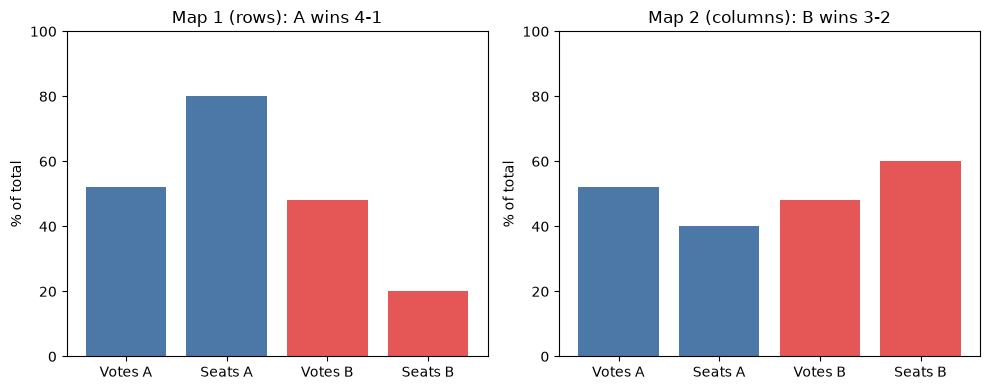

Chart saved to charts/phase1_seats_vs_votes.png


In [5]:
# Seats vs votes: the picture that tells the whole story
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, seats, title in [
    (axes[0], seats_rows, 'Map 1 (rows): A wins 4-1'),
    (axes[1], seats_cols, 'Map 2 (columns): B wins 3-2'),
]:
    ax.bar(['Votes A', 'Seats A', 'Votes B', 'Seats B'],
           [52, seats['A'] * 20, 48, seats['B'] * 20],
           color=['#4c78a8', '#4c78a8', '#e45756', '#e45756'])
    ax.set_ylim(0, 100)
    ax.set_ylabel('% of total')
    ax.set_title(title)
plt.tight_layout()
plt.savefig('../charts/phase1_seats_vs_votes.png', dpi=150)
plt.show()
print('Chart saved to charts/phase1_seats_vs_votes.png')

## Checkpoint — what you now know

- What a district is, and why redrawing its lines can change the winner without changing a single vote.
- **Packing:** cramming the opponent's voters into one district they win by a landslide.
- **Cracking:** spreading the opponent's voters thinly so they lose everywhere, narrowly.
- **Wasted votes** and the **efficiency gap**: the simplest way to measure how rigged a map is.

Next chapter: the same three ideas, but on a real state with real votes — North Carolina.
